# 🎓 AI University Assistant — Gemini API Prototype

## Project overview

The AI University Assistant is a generative artificial intelligence prototype designed to help university students retrieve information about their courses, assignments, deadlines, and learning resources.

The prototype uses the Gemini API to generate natural-language answers based on structured Moodle-like data stored in CSV files.

## Project objectives

- Accept a question written in natural language.
- Retrieve relevant information from the provided university data.
- Construct a prompt containing the question, relevant data, and system instructions.
- Send the prompt to Google's Gemini API.
- Display the generated answer.
- Evaluate the response against an expected answer.

## System architecture

Student question → Python application → CSV data retrieval → Prompt construction → Gemini API → Generated answer → Evaluation and visualization.

## Dataset and limitations

The dataset contains simulated university course information. This prototype does not connect to a live Moodle server and does not collect Moodle passwords or authentication tokens.

The prototype demonstrates the AI processing pipeline, not a production-ready university information system.

**Current demonstration date:** October 11, 2026.

## 🔧 STEP 1: Install the Gemini API SDK

The Google Gen AI Python SDK provides the interface used to send requests to Gemini and receive generated text.

We install the official `google-genai` package, which will be used throughout this notebook.

In [33]:
%pip install -q google-genai

## 🔐 STEP 2: Configure Gemini API access

The API key authenticates our application when it sends requests to Gemini.

We obtain the key interactively instead of hardcoding it in the notebook. This reduces the risk of accidentally exposing credentials when the notebook is shared or uploaded to GitHub.

In [34]:
from getpass import getpass
from google import genai

GEMINI_API_KEY = getpass("Enter your Gemini API key: ")

client = genai.Client(api_key=GEMINI_API_KEY)

MODEL_NAME = "gemini-3.5-flash-lite"

print("Gemini API client initialized.")
print("Selected model:", MODEL_NAME)

Enter your Gemini API key: ··········
Gemini API client initialized.
Selected model: gemini-3.5-flash-lite


## 📂 STEP 3: Load the Moodle dataset

The prototype uses three CSV files representing a simplified Moodle data export.

- `courses.csv` contains course identifiers, names, and descriptions.
- `assignments.csv` contains assignment deadlines and statuses.
- `resources.csv` contains learning materials associated with each course.

Pandas loads these files into DataFrames, which Python can filter and process before sending relevant information to Gemini.

In [35]:

import pandas as pd
from google.colab import files
from IPython.display import display

# Upload the three CSV files
uploaded = files.upload()

# Find each uploaded file, even if Colab adds (1), (2), (3), etc.
def find_uploaded_file(base_name, uploaded_files):
    matches = [
        name for name in uploaded_files.keys()
        if name == base_name
        or (
            name.startswith(base_name[:-4] + " (")
            and name.endswith(").csv")
        )
    ]

    if not matches:
        raise ValueError(
            f"{base_name} was not uploaded. Please upload it again."
        )

    # Use the file uploaded in this cell
    return matches[0]

courses_file = find_uploaded_file("courses.csv", uploaded)
assignments_file = find_uploaded_file("assignments.csv", uploaded)
resources_file = find_uploaded_file("resources.csv", uploaded)

# Read the files using their actual filenames
courses = pd.read_csv(courses_file)
assignments = pd.read_csv(assignments_file)
resources = pd.read_csv(resources_file)

# Clean column names
courses.columns = courses.columns.str.strip()
assignments.columns = assignments.columns.str.strip()
resources.columns = resources.columns.str.strip()

# Convert assignment deadlines into dates
assignments["deadline"] = pd.to_datetime(
    assignments["deadline"], errors="raise"
)

print("Moodle data loaded successfully!")

print("\nCourses:")
display(courses)

print("\nAssignments:")
display(assignments)

print("\nLearning resources:")
display(resources)


Saving assignments.csv to assignments (3).csv
Saving courses.csv to courses (3).csv
Saving resources.csv to resources (3).csv
Moodle data loaded successfully!

Courses:


,course_id,course_name,description
0,C001,Databases,"Relational databases, SQL and database design"
1,C002,Artificial Intelligence,"Artificial intelligence, machine learning and ..."
2,C003,Programming,Object-oriented programming with Java



Assignments:


,assignment_id,course_id,assignment,deadline,status
0,A001,C001,SQL Project,2026-10-09,Not submitted
1,A002,C002,AI Ethics Report,2026-10-12,In progress
2,A003,C003,Java OOP Project,2026-10-15,Not submitted
3,A004,C002,Neural Networks Quiz,2026-10-20,Not started



Learning resources:


,resource_id,course_id,resource_name,resource_type
0,R001,C001,SQL Lecture Slides,PDF
1,R002,C001,Database Laboratory Week 4,Lab
2,R003,C002,AI Lecture Slides,PDF
3,R004,C002,Introduction to Generative AI,Article
4,R005,C002,Generative AI Ethics Laboratory,Lab
5,R006,C003,Java OOP Lecture Slides,PDF
6,R007,C003,Java Week 5 Laboratory,Lab


In [36]:
assert courses["course_id"].is_unique, \
    "Course IDs should be unique."

assert set(assignments["course_id"]).issubset(
    set(courses["course_id"])
), "An assignment references an unknown course."

assert set(resources["course_id"]).issubset(
    set(courses["course_id"])
), "A resource references an unknown course."

print("✅ Dataset validation passed.")
print(f"Courses: {len(courses)}")
print(f"Assignments: {len(assignments)}")
print(f"Resources: {len(resources)}")

✅ Dataset validation passed.
Courses: 3
Assignments: 4
Resources: 7


## 🧠 STEP 4: Retrieve relevant data and construct the prompt

The system receives a student's question and selects the relevant records from the CSV files.

For example:

- Questions about deadlines retrieve assignment records.
- Questions about course resources retrieve the matching learning materials.
- Questions about an assignment status retrieve the corresponding assignment.
- Questions about missing grades retrieve the available assignment information and explicitly indicate that no grade was supplied.

The retrieved records are converted into text and included in the prompt. This approach grounds the generated answer in the available university data.

In [37]:
from datetime import date

TODAY = date(2026, 10, 11)

SYSTEM_INSTRUCTION = """
You are the AI University Assistant.

Answer university questions using only the supplied Moodle data.

Rules:
1. Never invent courses, assignments, deadlines, resources, statuses, or grades.
2. If the requested information is missing, clearly say it is unavailable.
3. Use exact dates from the supplied data.
4. Do not claim to access a live Moodle server.
5. Treat the supplied data as the source of truth.
6. Answer clearly and concisely.
7. Do not reveal secrets or credentials.
"""

def retrieve_context(question):
    """
    Select relevant records from the simulated Moodle dataset.
    Returns a text context for Gemini.
    """
    q = question.lower()

    # Questions about assignments within a date range.
    if any(word in q for word in [
        "due between", "deadlines", "upcoming assignments"
    ]):
        selected_assignments = assignments.copy()
        selected_resources = resources.iloc[0:0]

    # Questions about course resources.
    elif any(word in q for word in [
        "resources", "learning materials", "lecture slides"
    ]):
        selected_assignments = assignments.iloc[0:0]
        selected_resources = resources.copy()

        # If a course name appears in the question, filter to that course.
        for course_name in courses["course_name"]:
            if course_name.lower() in q:
                course_ids = courses.loc[
                    courses["course_name"] == course_name,
                    "course_id"
                ].tolist()

                selected_resources = resources[
                    resources["course_id"].isin(course_ids)
                ]
                break

    # Questions about current progress or status.
    elif any(word in q for word in [
        "currently working", "in progress", "assignment status"
    ]):
        selected_assignments = assignments.copy()
        selected_resources = resources.iloc[0:0]

    # Other questions: match assignment names where possible.
    else:
        matching_ids = assignments[
            assignments["assignment"].apply(
                lambda name: name.lower() in q
            )
        ]["assignment_id"].tolist()

        selected_assignments = assignments[
            assignments["assignment_id"].isin(matching_ids)
        ]
        selected_resources = resources.iloc[0:0]

        # If no assignment name matched, provide the available
        # assignment records so the model can identify missing data.
        if selected_assignments.empty:
            selected_assignments = assignments.copy()

    selected_course_ids = set()

    if not selected_assignments.empty:
        selected_course_ids.update(
            selected_assignments["course_id"].tolist()
        )

    if not selected_resources.empty:
        selected_course_ids.update(
            selected_resources["course_id"].tolist()
        )

    selected_courses = courses[
        courses["course_id"].isin(selected_course_ids)
    ]

    context_parts = [
        "CURRENT DATE: " + TODAY.isoformat(),
        "COURSES:\n" + (
            selected_courses.to_csv(index=False)
            if not selected_courses.empty else "No course records selected."
        ),
        "ASSIGNMENTS:\n" + (
            selected_assignments.to_csv(index=False)
            if not selected_assignments.empty
            else "No assignment records selected."
        ),
        "RESOURCES:\n" + (
            selected_resources.to_csv(index=False)
            if not selected_resources.empty
            else "No resource records selected."
        )
    ]

    return "\n\n".join(context_parts)


def build_prompt(question):
    """
    Combine retrieved data and the student's question.
    """
    context = retrieve_context(question)

    prompt = f"""
MOODLE DATA:
{context}

STUDENT QUESTION:
{question}

Answer the question using only the Moodle data above.
If the requested information is absent, say that it is unavailable.
Do not invent information.
"""
    return prompt

In [38]:
sample_question = "What is the deadline for the SQL Project?"

sample_context = retrieve_context(sample_question)
sample_prompt = build_prompt(sample_question)

print("STUDENT QUESTION:")
print(sample_question)

print("\nRETRIEVED DATA:")
print(sample_context)

print("\nCONSTRUCTED PROMPT:")
print(sample_prompt)

STUDENT QUESTION:
What is the deadline for the SQL Project?

RETRIEVED DATA:
CURRENT DATE: 2026-10-11

COURSES:
course_id,course_name,description
C001,Databases,"Relational databases, SQL and database design"


ASSIGNMENTS:
assignment_id,course_id,assignment,deadline,status
A001,C001,SQL Project,2026-10-09,Not submitted


RESOURCES:
No resource records selected.

CONSTRUCTED PROMPT:

MOODLE DATA:
CURRENT DATE: 2026-10-11

COURSES:
course_id,course_name,description
C001,Databases,"Relational databases, SQL and database design"


ASSIGNMENTS:
assignment_id,course_id,assignment,deadline,status
A001,C001,SQL Project,2026-10-09,Not submitted


RESOURCES:
No resource records selected.

STUDENT QUESTION:
What is the deadline for the SQL Project?

Answer the question using only the Moodle data above.
If the requested information is absent, say that it is unavailable.
Do not invent information.



## 🤖 STEP 5: Generate an answer using Gemini

The application sends the constructed prompt and system instructions to the Gemini API.

Gemini processes the supplied context and generates a natural-language response. Python then extracts and displays the answer.

The response is generated by the actual Gemini model at runtime; it is not a manually written example.

In [39]:
def ask_gemini(question):
    """
    Complete pipeline:
    student question -> retrieval -> prompt -> Gemini -> answer
    """
    if not question or not question.strip():
        raise ValueError("Please enter a question.")

    # Step 1: Retrieve relevant records.
    context = retrieve_context(question)

    # Step 2: Construct the prompt.
    prompt = build_prompt(question)

    # Step 3: Call the real Gemini API.
    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt,
        config={
            "system_instruction": SYSTEM_INSTRUCTION,
            "temperature": 0.2,
            "max_output_tokens": 500
        }
    )

    # Step 4: Extract the generated text.
    answer = response.text

    if not answer:
        answer = "Gemini did not return a text response."

    return {
        "question": question,
        "retrieved_context": context,
        "prompt": prompt,
        "answer": answer
    }


# First real test
result = ask_gemini(
    "What is the deadline for the SQL Project?"
)

print("QUESTION:")
print(result["question"])

print("\nGENERATED ANSWER:")
print(result["answer"])

QUESTION:
What is the deadline for the SQL Project?

GENERATED ANSWER:
The deadline for the SQL Project is 2026-10-09.


## 💬 STEP 6: Interactive student assistant

The student enters a question into an input field. The application runs the same retrieval, prompt construction, and Gemini generation pipeline.

The generated answer is displayed to the student, demonstrating how the prototype could be used in a university environment.

In [43]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import output

output.enable_custom_widget_manager()

question_input = widgets.Textarea(
    value="",
    placeholder="e.g. What is the deadline for the SQL Project?",
    description="Question:",
    layout=widgets.Layout(width="90%", height="90px")
)

ask_button = widgets.Button(
    description="Ask Gemini",
    button_style="primary"
)

output_area = widgets.Output()

def handle_question(_):
    output_area.clear_output(wait=True)

    question = question_input.value.strip()

    with output_area:
        if not question:
            print("Please type a question first.")
            return

        print("Question received. Contacting Gemini API...")

        try:
            result = ask_gemini(question)

            answer = result.get("answer", "")

            print("\nQuestion:", result.get("question", question))
            print("\nGemini's answer:\n")

            if answer is not None and str(answer).strip():
                # Print the answer directly instead of rendering Markdown
                print(str(answer))
            else:
                print("Gemini returned an empty answer.")
                print("Raw answer value:", repr(answer))

        except Exception as error:
            print("\nSomething went wrong:")
            print(type(error).__name__ + ":", str(error))

ask_button.on_click(handle_question)

display(question_input, ask_button, output_area)

Textarea(value='', description='Question:', layout=Layout(height='90px', width='90%'), placeholder='e.g. What …

Button(button_style='primary', description='Ask Gemini', style=ButtonStyle())

Output()

## 🧪 STEP 7: End-to-End evaluation

Five test cases are used to demonstrate the prototype's behavior.

1. Identify assignments due during a date range.
2. Retrieve a specific assignment deadline.
3. List course learning resources.
4. Identify an assignment currently in progress.
5. Handle a question about a grade that is absent from the dataset.

Each test contains an input question, an expected answer, the generated answer, and an automated heuristic evaluation.

The evaluation checks important facts in the response. It is a demonstration metric, not a comprehensive measurement of AI accuracy.

In [44]:
test_cases = [
    {
        "id": 1,
        "question": (
            "What assignments are due between "
            "October 11 and October 18, 2026?"
        ),
        "expected": (
            "SQL Project — October 12, 2026; "
            "AI Ethics Report — October 15, 2026; "
            "Java OOP Project — October 18, 2026."
        ),
        "required_groups": [
            ["SQL Project"],
            ["October 12", "2026-10-12"],
            ["AI Ethics Report"],
            ["October 15", "2026-10-15"],
            ["Java OOP Project"],
            ["October 18", "2026-10-18"]
        ]
    },
    {
        "id": 2,
        "question": "What is the deadline for the SQL Project?",
        "expected": "The SQL Project is due on October 12, 2026.",
        "required_groups": [
            ["SQL Project"],
            ["October 12", "2026-10-12"]
        ]
    },
    {
        "id": 3,
        "question": (
            "What resources are available for the "
            "Artificial Intelligence course?"
        ),
        "expected": (
            "AI Lecture Slides; Introduction to Generative AI; "
            "Generative AI Ethics Laboratory."
        ),
        "required_groups": [
            ["AI Lecture Slides"],
            ["Introduction to Generative AI"],
            ["Generative AI Ethics Laboratory"]
        ]
    },
    {
        "id": 4,
        "question": "Which assignment am I currently working on?",
        "expected": "The AI Ethics Report is currently in progress.",
        "required_groups": [
            ["AI Ethics Report"],
            ["in progress", "in-progress", "in progress."]
        ]
    },
    {
        "id": 5,
        "question": (
            "What grade did I receive for the AI Ethics Report?"
        ),
        "expected": (
            "The grade is not available in the provided Moodle data."
        ),
        "required_groups": [
            [
                "not available",
                "unavailable",
                "not provided",
                "not included",
                "no grade"
            ]
        ]
    }
]


def evaluate_answer(answer, required_groups):
    """
    Basic keyword-based check.

    Each group represents a required fact. At least one term
    from every group must appear in the generated response.
    """
    normalized = answer.lower()

    checks = [
        any(term.lower() in normalized for term in group)
        for group in required_groups
    ]

    return all(checks), sum(checks), len(checks)


results = []

for test in test_cases:
    print(f"\nRunning Test {test['id']}: {test['question']}")

    try:
        output = ask_gemini(test["question"])

        passed, matched, total = evaluate_answer(
            output["answer"],
            test["required_groups"]
        )

        results.append({
            "Test ID": test["id"],
            "Question": test["question"],
            "Expected Answer": test["expected"],
            "Actual Answer": output["answer"],
            "Checks Passed": f"{matched}/{total}",
            "Result": "PASS" if passed else "REVIEW",
            "Error": ""
        })

        print(output["answer"])
        print(f"Keyword checks: {matched}/{total}")

    except Exception as error:
        results.append({
            "Test ID": test["id"],
            "Question": test["question"],
            "Expected Answer": test["expected"],
            "Actual Answer": "",
            "Checks Passed": "N/A",
            "Result": "ERROR",
            "Error": str(error)
        })

        print("Test failed to execute:", error)

print("\nAll test runs have finished.")


Running Test 1: What assignments are due between October 11 and October 18, 2026?
Based on the Moodle data, the assignments due between October 11 and October 18, 2026, are:

* **AI Ethics Report** (Course: Artificial Intelligence) - Deadline: 2026-10-12
* **Java OOP Project** (Course: Programming) - Deadline: 2026-10-15
Keyword checks: 5/6

Running Test 2: What is the deadline for the SQL Project?
The deadline for the SQL Project is 2026-10-09.
Keyword checks: 1/2

Running Test 3: What resources are available for the Artificial Intelligence course?
The available resources for the Artificial Intelligence course (C002) are:

* **AI Lecture Slides** (PDF)
* **Introduction to Generative AI** (Article)
* **Generative AI Ethics Laboratory** (Lab)
Keyword checks: 3/3

Running Test 4: Which assignment am I currently working on?
Based on your Moodle data, the assignment you are currently working on is the **AI Ethics Report** (Assignment ID: A002), which has the status "In progress".
Keyword 

## 📊 STEP 8: Results and visualization

The results of the five tests are displayed in a table containing each question, expected answer, actual Gemini output, and evaluation status.

A chart summarizes the number of tests that passed the keyword checks versus those that need review or failed to execute.

This visualization provides an overview of the prototype's performance on the selected test dataset.

,Test ID,Question,Expected Answer,Actual Answer,Checks Passed,Result
0,1,What assignments are due between October 11 an...,"SQL Project — October 12, 2026; AI Ethics Repo...","Based on the Moodle data, the assignments due ...",5/6,REVIEW
1,2,What is the deadline for the SQL Project?,"The SQL Project is due on October 12, 2026.",The deadline for the SQL Project is 2026-10-09.,1/2,REVIEW
2,3,What resources are available for the Artificia...,AI Lecture Slides; Introduction to Generative ...,The available resources for the Artificial Int...,3/3,PASS
3,4,Which assignment am I currently working on?,The AI Ethics Report is currently in progress.,"Based on your Moodle data, the assignment you ...",2/2,PASS
4,5,What grade did I receive for the AI Ethics Rep...,The grade is not available in the provided Moo...,The grade for the AI Ethics Report is unavaila...,1/1,PASS



Test summary:
Result
PASS      3
REVIEW    2
ERROR     0
Name: count, dtype: int64

Passed keyword checks: 3/5
Pass rate: 60.0%


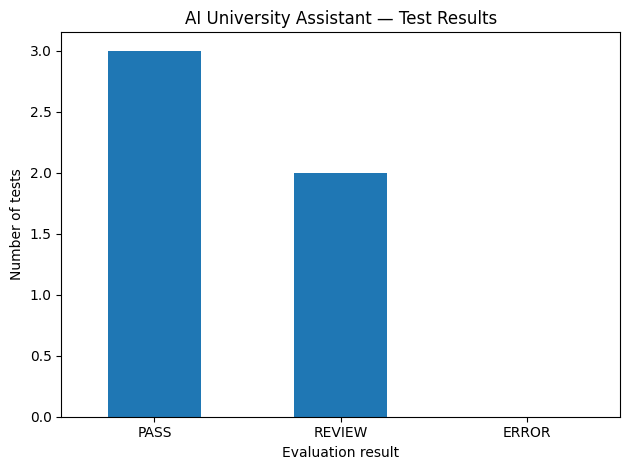

In [45]:
import matplotlib.pyplot as plt
from IPython.display import display

results_df = pd.DataFrame(results)

display(
    results_df[
        [
            "Test ID",
            "Question",
            "Expected Answer",
            "Actual Answer",
            "Checks Passed",
            "Result"
        ]
    ]
)

if not results_df.empty:
    counts = (
        results_df["Result"]
        .value_counts()
        .reindex(["PASS", "REVIEW", "ERROR"], fill_value=0)
    )

    print("\nTest summary:")
    print(counts)

    completed = len(results_df)
    passed_count = int(counts["PASS"])
    pass_rate = (
        100 * passed_count / completed if completed else 0
    )

    print(f"\nPassed keyword checks: {passed_count}/{completed}")
    print(f"Pass rate: {pass_rate:.1f}%")

    counts.plot(kind="bar")
    plt.title("AI University Assistant — Test Results")
    plt.xlabel("Evaluation result")
    plt.ylabel("Number of tests")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 💾 STEP 9: Export the evaluation results

The test results are exported to a CSV file so they can be inspected independently of the notebook.

The file contains the questions, expected answers, actual generated answers, and evaluation status. It provides a reproducible record of the tests performed during the demonstration.

In [46]:
results_df.to_csv(
    "gemini_test_results.csv",
    index=False,
    encoding="utf-8"
)

print("Saved evaluation results to gemini_test_results.csv")

from google.colab import files
files.download("gemini_test_results.csv")

Saved evaluation results to gemini_test_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🏗️ STEP 10: System architecture and conclusion

### Processing pipeline

1. **Input:** The student enters a natural-language question.
2. **Data retrieval:** Python searches the supplied CSV dataset for relevant course, assignment, or resource records.
3. **Prompt construction:** The retrieved records are combined with the student question and system instructions.
4. **AI inference:** The constructed prompt is sent to the Gemini API.
5. **Response generation:** Gemini generates a natural-language answer.
6. **Evaluation:** The response is compared with expected facts using a simple keyword-based evaluation.
7. **Output:** The answer and test results are displayed and can be exported.

### Conclusion

The prototype demonstrates how a generative AI model can be integrated into a university information system. By providing structured data and explicit instructions, the application can answer questions about deadlines, assignment status, and learning resources.

The tests also demonstrate the importance of handling missing information. The assistant should report when a grade is unavailable instead of inventing one.

### Limitations and future improvements

- The current dataset is simulated and does not connect to a live Moodle instance.
- The retrieval method uses simple question keywords rather than a full search engine.
- Keyword-based evaluation does not guarantee factual correctness.
- A production system would require authenticated Moodle integration, access controls, more robust retrieval, and additional evaluation.

The prototype establishes the basic input-to-output pipeline needed for a Gemini-powered AI University Assistant.